In [2]:
!pip install tensorflow numpy opencv-python scikit-learn matplotlib kagglehub


In [3]:
import os
import shutil
import cv2
import numpy as np
from glob import glob
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
import kagglehub

/opt/anaconda3/envs/tf312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
def download_dataset():
    print("Downloading Kaggle dataset...")
    kaggle_path = kagglehub.dataset_download("ahemateja19bec1025/covid-xray-dataset")
    print("Kaggle raw path:", kaggle_path)

    # Local destination
    local_data_dir = os.path.join(os.getcwd(), "data")
    os.makedirs(local_data_dir, exist_ok=True)

    print("Copying dataset to ./data ...")
    shutil.copytree(kaggle_path, local_data_dir, dirs_exist_ok=True)

    print("Dataset available at:", local_data_dir)
    return local_data_dir

In [5]:
def load_images(data_dir, img_size=224):
    print("Loading and preprocessing images...")

    # Based on your dataset structure
    covid_dir = os.path.join(data_dir, "DATA", "DATA", "0")
    normal_dir = os.path.join(data_dir, "DATA", "DATA", "1")

    # Glob all image formats
    extensions = ["*.jpg", "*.jpeg", "*.png"]

    covid_paths, normal_paths = [], []

    for ext in extensions:
        covid_paths.extend(glob(os.path.join(covid_dir, ext)))
        normal_paths.extend(glob(os.path.join(normal_dir, ext)))

    print(f"Found {len(covid_paths)} COVID images.")
    print(f"Found {len(normal_paths)} Normal images.")

    X, y = [], []

    # Process COVID images
    print("Processing COVID images...")
    for path in covid_paths:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue
        img = cv2.resize(img, (img_size, img_size))
        X.append(img)
        y.append(0)

    # Process Normal images
    print("Processing Normal images...")
    for path in normal_paths:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue
        img = cv2.resize(img, (img_size, img_size))
        X.append(img)
        y.append(1)

    print("Converting to NumPy arrays...")
    X = np.array(X, dtype="float32") / 255.0
    X = X.reshape(-1, img_size, img_size, 1)
    y = np.array(y, dtype="int64")

    print(f"Final dataset size: {len(X)}")
    return X, y

=== COVID X-Ray Dataset (Keras Version) ===
Dataset already exists.
Loading and preprocessing images...
Found 1301 COVID images.
Found 1790 Normal images.
Processing COVID images...
Processing Normal images...
Converting to NumPy arrays...
Final dataset size: 3091


/opt/anaconda3/envs/tf312/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 30s 215ms/step - accuracy: 0.7813 - loss: 0.4606 - val_accuracy: 0.9569 - val_loss: 0.1482
Epoch 2/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 30s 224ms/step - accuracy: 0.9302 - loss: 0.1987 - val_accuracy: 0.9504 - val_loss: 0.1525
Epoch 3/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 31s 229ms/step - accuracy: 0.9487 - loss: 0.1394 - val_accuracy: 0.9569 - val_loss: 0.1152
Epoch 4/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 32s 238ms/step - accuracy: 0.9561 - loss: 0.1143 - val_accuracy: 0.9698 - val_loss: 0.0894
Epoch 5/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 38s 280ms/step - accuracy: 0.9547 - loss: 0.1048 - val_accuracy: 0.9569 - val_loss: 0.1247
Epoch 6/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 50s 368ms/step - accuracy: 0.9713 - loss: 0.0780 - val_accuracy: 0.9677 - val_loss: 0.1089
Epoch 7/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 53s 387ms/step - accuracy: 0.9778 - loss: 0.0534 - val_accuracy: 0.9418 - val_loss: 0.2081
Epoch 8/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 51s 374ms/step - accuracy: 0.9783 - loss: 0

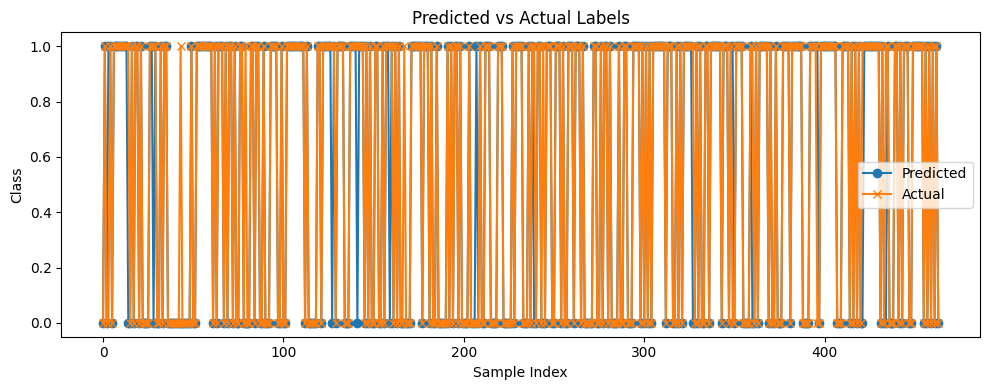

Saving predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 156ms/step
Saved keras_predictions.npy


In [6]:
def build_model(img_size=224):
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation="relu", input_shape=(img_size, img_size, 1)),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ---------------------------------------------------------
# 4. Evaluate and print predictions
# ---------------------------------------------------------

def evaluate_model(model, X_test, y_test):
    loss, acc = model.evaluate(X_test, y_test)
    print(f"Test Accuracy: {acc:.4f}")

    preds = (model.predict(X_test) > 0.5).astype("int32").reshape(-1)

    print("\nPredictions:")
    for i in range(len(preds)):
        print(f"Image {i}: Predicted={preds[i]}, Actual={y_test[i]}")

    # Simple plot
    plt.figure(figsize=(10, 4))
    plt.plot(preds, label="Predicted", marker="o")
    plt.plot(y_test, label="Actual", marker="x")
    plt.title("Predicted vs Actual Labels")
    plt.xlabel("Sample Index")
    plt.ylabel("Class")
    plt.legend()
    plt.tight_layout()
    plt.savefig("keras_prediction_plot.png")
    plt.show()


# ---------------------------------------------------------
# MAIN SCRIPT
# ---------------------------------------------------------

if __name__ == "__main__":
    print("=== COVID X-Ray Dataset (Keras Version) ===")

    # Download dataset if needed
    data_dir = os.path.join(os.getcwd(), "data")
    if not os.path.exists(os.path.join(data_dir, "DATA", "DATA")):
        print("Dataset not found. Downloading...")
        data_dir = download_dataset()
    else:
        print("Dataset already exists.")

    # Load + preprocess data
    X, y = load_images(data_dir)

    if len(X) == 0:
        raise RuntimeError("No images found. Dataset structure may have changed.")

    # Train / val / test split
    X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.3, stratify=y)
    X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp)

    np.save("y_test_true.npy", y_test)

    # Build CNN
    model = build_model()

    # Train
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=16
    )

    # Evaluate + print results
    evaluate_model(model, X_test, y_test)

    print("Saving predictions...")
    preds = (model.predict(X_test) > 0.5).astype("int32").reshape(-1)
    np.save("keras_predictions.npy", preds)
    print("Saved keras_predictions.npy")



=== Model Evaluation Metrics ===
Accuracy: 0.9612
AUC: 0.9637
Precision: 0.9845
Recall: 0.9478
F1 Score: 0.9658
Manually Implemented CNN Confusion Matrix:
[[192   4]
 [ 14 254]]


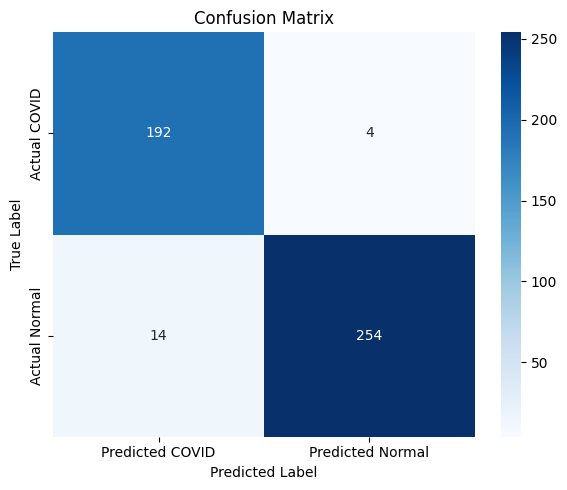

In [8]:
# Summary statistics + data visualizations for CNN from scratch
# Accuracy, AUC, precision, recall, f1, confusion matrix

from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns

# Load predictions & true labels
preds = np.load("keras_predictions.npy")
y_test = np.load("y_test_true.npy")

# Metrics
accuracy = accuracy_score(y_test, preds)
auc = roc_auc_score(y_test, preds)
precision = precision_score(y_test, preds)
recall = recall_score(y_test, preds)
f1 = f1_score(y_test, preds)
conf_matrix = confusion_matrix(y_test, preds)

# Print metrics
print("=== Model Evaluation Metrics ===")
print(f"Accuracy: {accuracy:.4f}")
print(f"AUC: {auc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")    
print("Manually Implemented CNN Confusion Matrix:")
print(conf_matrix)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted COVID", "Predicted Normal"],
            yticklabels=["Actual COVID", "Actual Normal"])
plt.title("Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()